**Disciplina:** Tópicos Especiais de Energia – Transferência de Calor utilizando PINNs (UFABC, 3º quadrimestre de 2026)
**Professores:** Prof. Dr. Daniel Jonas Dezan e Prof. MSc. Paulo de Souza Silva
**Aluno:** _preencher com o nome completo_
**Lista 2 – Condução e Solução de Blasius em Python**

Obs.: notebook desenvolvido com auxílio de ferramentas de IA, como permitido no enunciado; o código e os resultados foram executados e conferidos.

# **Exercício 4 – Método da capacitância global e influência do número de Biot**

**Notebook de apoio:** `Aula03_Parte3_Transiente_CapacitanciaGlobal.ipynb`

Como pede o enunciado, **não reimplementamos** os métodos. As células de código abaixo reproduzem, **sem alterações**, a solução de referência por diferenças finitas e a comparação com a capacitância global do notebook de apoio, para que os gráficos e números usados nas respostas fiquem visíveis aqui. A única exceção é a chamada `np.trapz`, que foi trocada por `np.trapezoid`, nome atual da função nas versões recentes do NumPy.

**Problema do notebook:** bloco plano de espessura total $2L$ ($L = 0{,}01$ m), inicialmente a $T_0 = 400\,^\circ$C, imerso num fluido a $T_\infty = 300\,^\circ$C com $h = 300$ W/(m²·K). Por simetria, resolve-se meia espessura, com $\partial T/\partial x = 0$ no centro e convecção na superfície.

$$
Bi = \frac{h L_c}{k}, \qquad L_c = \frac{V}{A_s} = L, \qquad
\tau_t = \frac{\rho c_p L_c}{h}, \qquad
\frac{\theta}{\theta_0} = \exp\!\left(-\frac{t}{\tau_t}\right).
$$

> A execução leva cerca de 2 minutos: o caso do aço usa um passo de tempo explícito muito pequeno (≈2,8 milhões de passos).

In [1]:
# Bibliotecas utilizadas
import os
import numpy as np                  # funções matemáticas e vetores
import matplotlib.pyplot as plt     # gráficos

os.makedirs("figuras", exist_ok=True)   # pasta onde as figuras são salvas
plt.rcParams["figure.dpi"] = 110

# ---- Código do notebook de apoio (sem alterações de método) ----
L = 0.01       # metade da espessura do bloco [m]
h = 300.0      # coeficiente de convecção [W/(m² K)]
T0 = 400.0     # temperatura inicial [°C]
Tinf = 300.0   # temperatura do fluido [°C]
N = 51         # número de pontos da malha espacial
Fo_escolhido = 0.2

def bloco_diferencas_finitas(k, rho, cp, tempo_final, n_tempos=601):
    x = np.linspace(0.0, L, N)
    dx = x[1] - x[0]
    alpha = k / (rho * cp)
    dt_max = Fo_escolhido * dx**2 / alpha
    n_passos = int(np.ceil(tempo_final / dt_max))
    dt = tempo_final / n_passos
    indices_saida = np.linspace(0, n_passos, n_tempos).round().astype(int)
    tempos = indices_saida * dt

    T = np.full(N, T0)
    temperaturas = np.zeros((N, n_tempos))
    temperaturas[:, 0] = T
    proxima_saida = 1

    for passo in range(1, n_passos + 1):
        dTdt = np.zeros_like(T)
        dTdt[0] = alpha * 2.0 * (T[1] - T[0]) / dx**2                      # simetria no centro
        dTdt[1:-1] = alpha * (T[2:] - 2.0 * T[1:-1] + T[:-2]) / dx**2       # pontos internos
        Tfantasma = T[-2] - 2.0 * dx * h / k * (T[-1] - Tinf)               # convecção (ponto fantasma)
        dTdt[-1] = alpha * (Tfantasma - 2.0 * T[-1] + T[-2]) / dx**2
        T = T + dt * dTdt                                                   # Euler explícito
        while proxima_saida < n_tempos and passo >= indices_saida[proxima_saida]:
            temperaturas[:, proxima_saida] = T
            proxima_saida += 1

    print(f"dx = {dx:.3e} m | dt = {dt:.3e} s | Fo = {alpha * dt / dx**2:.4f} | passos = {n_passos}")
    return tempos, x, temperaturas

In [2]:
casos = {
    "Bi baixo - aço":     {"k": 45.0, "rho": 7800.0, "cp": 500.0},
    "Bi alto - isolante": {"k": 0.3,  "rho": 1200.0, "cp": 1800.0},
}

Lc = L
resultados = {}
for nome, p in casos.items():
    k, rho, cp = p["k"], p["rho"], p["cp"]
    Bi = h * Lc / k
    tau = rho * cp * Lc / h
    print(f"\n{nome}:")
    tempo, x, temperatura = bloco_diferencas_finitas(k=k, rho=rho, cp=cp, tempo_final=15.0 * tau)

    theta = (temperatura - Tinf) / (T0 - Tinf)
    theta_media = np.trapezoid(theta, x, axis=0) / L        # média espacial (DF)
    theta_lumped = np.exp(-tempo / tau)                     # capacitância global
    erro = np.abs(theta_media - theta_lumped)

    resultados[nome] = dict(Bi=Bi, tau=tau, tempo=tempo, x=x, theta=theta,
                            theta_media=theta_media, theta_lumped=theta_lumped, erro=erro)
    print(f"Bi = {Bi:.4f} | tau = {tau:.1f} s | erro máximo |θ_média − θ_lumped| = {erro.max():.4f}")


Bi baixo - aço:


dx = 2.000e-04 m | dt = 6.933e-04 s | Fo = 0.2000 | passos = 2812500
Bi = 0.0667 | tau = 130.0 s | erro máximo |θ_média − θ_lumped| = 0.0081

Bi alto - isolante:


dx = 2.000e-04 m | dt = 5.760e-02 s | Fo = 0.2000 | passos = 18750
Bi = 10.0000 | tau = 72.0 s | erro máximo |θ_média − θ_lumped| = 0.4487


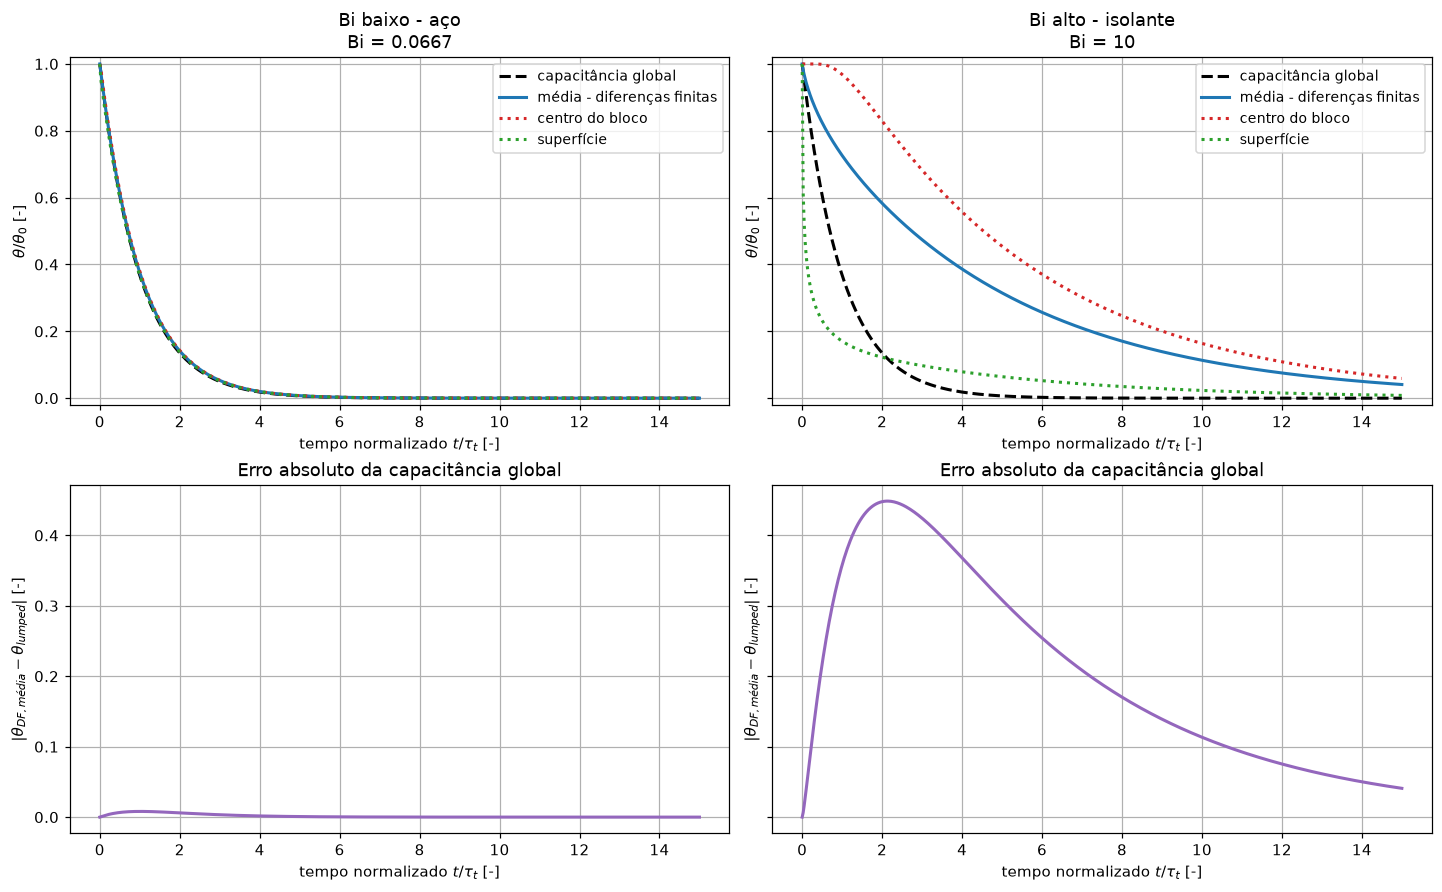

In [3]:
# Gráficos do notebook de apoio: θ/θ0 × t/τ e erro da capacitância global
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey="row", constrained_layout=True)
for coluna, (nome, r) in enumerate(resultados.items()):
    tn = r["tempo"] / r["tau"]
    ax = axes[0, coluna]
    ax.plot(tn, r["theta_lumped"], "k--", lw=2, label="capacitância global")
    ax.plot(tn, r["theta_media"], color="tab:blue", lw=2, label="média - diferenças finitas")
    ax.plot(tn, r["theta"][0, :], ":", color="tab:red", lw=2, label="centro do bloco")
    ax.plot(tn, r["theta"][-1, :], ":", color="tab:green", lw=2, label="superfície")
    ax.set_title(f"{nome}\nBi = {r['Bi']:.3g}")
    ax.set_xlabel(r"tempo normalizado $t/\tau_t$ [-]")
    ax.set_ylabel(r"$\theta/\theta_0$ [-]")
    ax.set_ylim(-0.02, 1.02)
    ax.grid(True)
    ax.legend(fontsize=9)

    ax = axes[1, coluna]
    ax.plot(tn, r["erro"], color="tab:purple", lw=2)
    ax.set_title("Erro absoluto da capacitância global")
    ax.set_xlabel(r"tempo normalizado $t/\tau_t$ [-]")
    ax.set_ylabel(r"$|\theta_{DF,média}-\theta_{lumped}|$ [-]")
    ax.grid(True)
plt.savefig("figuras/ex4_theta_vs_t_tau.png", dpi=300, bbox_inches="tight")
plt.show()

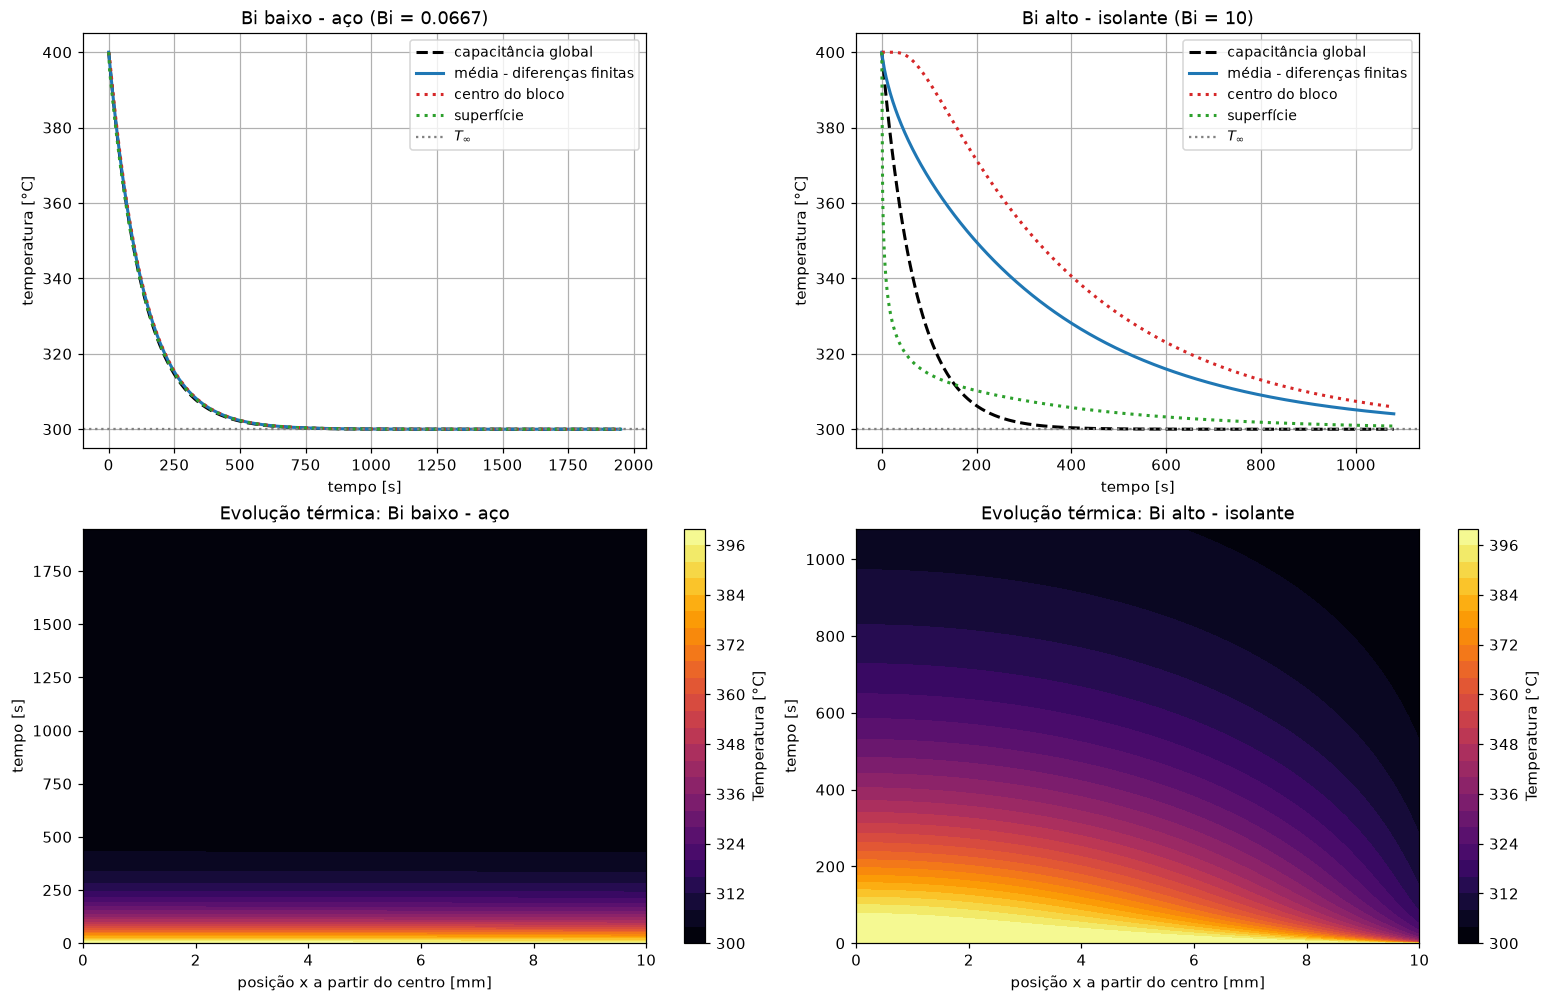

In [4]:
# Temperaturas reais (°C) e mapas x–t, como no notebook de apoio
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for coluna, (nome, r) in enumerate(resultados.items()):
    conv = lambda th: Tinf + (T0 - Tinf) * th
    ax = axes[0, coluna]
    ax.plot(r["tempo"], conv(r["theta_lumped"]), "k--", lw=2, label="capacitância global")
    ax.plot(r["tempo"], conv(r["theta_media"]), color="tab:blue", lw=2, label="média - diferenças finitas")
    ax.plot(r["tempo"], conv(r["theta"][0, :]), ":", color="tab:red", lw=2, label="centro do bloco")
    ax.plot(r["tempo"], conv(r["theta"][-1, :]), ":", color="tab:green", lw=2, label="superfície")
    ax.axhline(Tinf, color="gray", ls=":", label=r"$T_\infty$")
    ax.set_title(f"{nome} (Bi = {r['Bi']:.3g})")
    ax.set_xlabel("tempo [s]")
    ax.set_ylabel("temperatura [°C]")
    ax.set_ylim(Tinf - 5, T0 + 5)
    ax.grid(True)
    ax.legend(fontsize=9)

    X, Tempo = np.meshgrid(r["x"] * 1000, r["tempo"])
    mapa = axes[1, coluna].contourf(X, Tempo, conv(r["theta"]).T, levels=30, cmap="inferno",
                                    vmin=Tinf, vmax=T0)
    axes[1, coluna].set_title(f"Evolução térmica: {nome}")
    axes[1, coluna].set_xlabel("posição x a partir do centro [mm]")
    axes[1, coluna].set_ylabel("tempo [s]")
    fig.colorbar(mapa, ax=axes[1, coluna], label="Temperatura [°C]")
plt.savefig("figuras/ex4_temperaturas_e_mapas.png", dpi=300, bbox_inches="tight")
plt.show()

### **Tabela de apoio às respostas** (valores lidos das curvas acima)

In [5]:
import pandas as pd
linhas = []
for nome, r in resultados.items():
    tn = r["tempo"] / r["tau"]
    for alvo in [0.5, 1.0, 2.0, 3.0]:
        i = np.argmin(np.abs(tn - alvo))
        linhas.append({"caso": nome, "Bi": round(r["Bi"], 4), "t/τ": alvo,
                       "lumped": r["theta_lumped"][i], "média DF": r["theta_media"][i],
                       "centro": r["theta"][0, i], "superfície": r["theta"][-1, i],
                       "centro − superfície": r["theta"][0, i] - r["theta"][-1, i]})
tabela = pd.DataFrame(linhas)
print("Valores de θ/θ0 [-]:\n")
print(tabela.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Valores de θ/θ0 [-]:

              caso      Bi    t/τ  lumped  média DF  centro  superfície  centro − superfície
    Bi baixo - aço  0.0667 0.5000  0.6065    0.6131  0.6198      0.5997               0.0201
    Bi baixo - aço  0.0667 1.0000  0.3679    0.3760  0.3801      0.3678               0.0123
    Bi baixo - aço  0.0667 2.0000  0.1353    0.1414  0.1429      0.1383               0.0046
    Bi baixo - aço  0.0667 3.0000  0.0498    0.0532  0.0537      0.0520               0.0017
Bi alto - isolante 10.0000 0.5000  0.6065    0.8243  0.9985      0.2322               0.7664
Bi alto - isolante 10.0000 1.0000  0.3679    0.7260  0.9684      0.1705               0.7979
Bi alto - isolante 10.0000 2.0000  0.1353    0.5832  0.8292      0.1225               0.7068
Bi alto - isolante 10.0000 3.0000  0.0498    0.4741  0.6824      0.0973               0.5851


## **Respostas**

### **a) Hipótese principal**

A capacitância global supõe que a **temperatura dentro do sólido é uniforme em cada instante**: $T = T(t)$, sem dependência da posição. Isso vale quando a condução interna é muito mais "fácil" que a troca de calor com o fluido. O calor redistribui-se dentro do corpo quase instantaneamente, comparado à rapidez com que sai pela superfície, e o gargalo fica todo na convecção.

Se não há diferença de temperatura relevante entre o centro e a superfície, uma única temperatura descreve o bloco inteiro. O balanço de energia vira uma EDO simples, $\rho V c\,dT/dt = -hA_s(T-T_\infty)$, cuja solução é a exponencial $\theta/\theta_0 = e^{-t/\tau_t}$.

### **b) Números de Biot**

| Caso | $k$ [W/(m·K)] | $Bi = hL/k$ | $\tau_t$ [s] | Capacitância global |
|---|---:|---:|---:|---|
| Aço | 45 | **0,067** | 130 | **Adequada** ($Bi < 0{,}1$) |
| Isolante | 0,3 | **10** | 72 | **Inadequada** ($Bi \gg 0{,}1$) |

O critério usual é $Bi < 0{,}1$. O aço está abaixo do limite; o isolante está 100 vezes acima.

### **c) Comportamento exponencial e papel de $\tau$**

O decaimento exponencial significa que a **taxa de resfriamento é proporcional ao excesso de temperatura** $\theta = T - T_\infty$. No início, com o bloco bem mais quente que o fluido, a perda de calor é rápida; à medida que $\theta$ diminui, a troca também diminui, e a temperatura só se aproxima de $T_\infty$ assintoticamente.

A constante de tempo $\tau_t = \rho c_p L_c / h$ é a razão entre a **capacidade térmica** do corpo e a **condutância convectiva**, ou seja, uma resistência térmica vezes uma capacitância, como num circuito RC. Ela define a escala de tempo da resposta: em $t=\tau_t$ resta $1/e \approx 36{,}8\%$ do excesso inicial, em $3\tau_t$ cerca de 5% e em $5\tau_t$ menos de 1%.

Ao plotar contra $t/\tau_t$, a curva da capacitância global é **a mesma para qualquer material**, o que permite comparar os dois casos diretamente.

### **d) Comparação das quatro respostas**

**Aço ($Bi = 0{,}067$):** as quatro curvas praticamente se sobrepõem. Em $t/\tau = 1$, a capacitância global dá $0{,}368$, a média por DF $0{,}376$, o centro $0{,}380$ e a superfície $0{,}368$. O maior erro da capacitância global ao longo do tempo é de apenas $0{,}008$, menos de 1 °C para $\theta_0 = 100$ °C. A diferença centro–superfície fica em torno de $0{,}01$–$0{,}02$, porque o aço conduz bem: o calor chega à superfície tão rápido quanto sai por convecção.

**Isolante ($Bi = 10$):** as curvas se separam completamente. Em $t/\tau = 1$, a capacitância global prevê $0{,}368$, mas a média por DF ainda está em $0{,}726$, o centro quase não mudou ($0{,}968$) e a superfície já caiu para $0{,}171$. O erro máximo da capacitância global chega a $0{,}45$ (≈45 °C) perto de $t/\tau \approx 2$.

A superfície acompanha o fluido rapidamente, enquanto o interior fica "preso" pela baixa condutividade. O bloco real resfria **muito mais devagar** do que o modelo prevê: a resistência que manda é a de condução, que o modelo ignora.

### **e) Por que o método falha com $Bi$ alto**

$Bi = R_{cond}/R_{conv}$. Com $Bi = 10$, a resistência à condução dentro do bloco é dez vezes maior que a resistência convectiva, então a maior parte da diferença de temperatura fica **dentro do sólido**, não na camada de fluido. Formam-se **gradientes internos** fortes: no mapa $x$–$t$ do isolante as isotermas ficam concentradas junto à superfície, e em $t/\tau = 1$ a diferença centro–superfície é de cerca de $0{,}80\,\theta_0$ (≈80 °C).

Como a capacitância global usa uma temperatura única, ela não representa nenhuma região corretamente. Ela não acompanha a superfície, que esfria mais rápido, nem o centro, que esfria mais devagar, e erra até a média, porque usa $\tau = \rho c L/h$ como se só a convecção limitasse a troca. Na prática, o tempo de resfriamento é governado pela difusão, $\sim L^2/\alpha$.

### **f) Quando usar métodos numéricos**

Diferenças finitas (ou outro método que resolva $T(x,t)$) são mais adequadas quando:

- $Bi \gtrsim 0{,}1$, ou seja, materiais de baixa condutividade, peças espessas ou convecção intensa;
- interessa a temperatura **local** (máxima no centro, mínima na superfície), como em choque térmico, tensões térmicas, cura ou cozimento de alimentos;
- há geometria complexa, propriedades que variam com a temperatura, geração interna ou condições de contorno que mudam no tempo ou diferem entre faces;
- há várias camadas de materiais ou contato com resistências diferentes.

A capacitância global continua útil como **estimativa rápida** quando $Bi < 0{,}1$, como no termopar do notebook de apoio. Ela também serve para verificar a ordem de grandeza de uma simulação.

### **Validade e limitações**

O método é exato apenas no limite $Bi \to 0$. Para $Bi < 0{,}1$ o erro é pequeno, como mostra o aço, com menos de 1% de $\theta_0$. Acima disso, ele **superestima a velocidade de resfriamento** e não fornece informação espacial. Por isso, o número de Biot deve ser sempre verificado antes de aplicá-lo.